> #  **Notebook Final**
Asma BEN HMIDA & Lilia NEKILI & Siwar DAGHAR

# **Importation des Bibliothèques**

In [1]:
import time
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # plotting 
import seaborn # another plotting libary, nice visualizations
import csv

# **Visualition des données**

On commence par importer nos données d'entrainement et de test grâce à la fonction *pandas.read_csv* qui nous sert à lire des fichier csv.

In [2]:
path_to_data = "/kaggle/input/are-sd-2024-emissions-co2-du-mix-electrique/"

train = pd.read_csv(path_to_data + 'train.csv', index_col='DateTime', parse_dates=True)
test = pd.read_csv(path_to_data+"prev.csv")

On centre et réduit les valeurs des variables aléatoires afin d'améliorer la performance.

In [3]:
def standardize_data(data):
    """Centre et réduit les colonnes 
    Args :
    data : un DataFrame pandas contenant les données à standardiser
    
    Retourne :
    les données standardisées sous forme de pandas DataFrame
    """
    variables= ["Temperature", "Humidity", "Nebulosity", "Precipitation", "PositionDansAnnee", "WindSpeed"]
    for i in variables:
        data[i]=(data[i]*np.mean(data[i]))/np.std(data[i])
    return data

On visualise les 10 premières lignes du tableau des données d'entrainement grace à la fonction *.head()* .

In [4]:
train.head()

,MixProdElec,EmissionCO2,PositionDansAnnee,Annee,Mois,DemiHeure,Jour,JourFerie,JourFerieType,VacancesZoneA,VacancesZoneB,VacancesZoneC,Temperature,Nebulosity,Humidity,WindSpeed,Precipitation
DateTime,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,Normal,932.5575,0.000000,2016,janvier,0,vendredi,True,1janvier,True,True,True,6.470270,88.761905,91.216216,2.264865,-0.013514
2016-01-01 00:30:00,Normal,912.7485,0.000057,2016,janvier,1,vendredi,True,1janvier,True,True,True,6.324798,88.557998,91.466505,2.226276,-0.010407
2016-01-01 01:00:00,Normal,906.8480,0.000114,2016,janvier,2,vendredi,True,1janvier,True,True,True,6.179325,88.354090,91.716794,2.187688,-0.007300
2016-01-01 01:30:00,Normal,903.3600,0.000171,2016,janvier,3,vendredi,True,1janvier,True,True,True,6.033853,88.150183,91.967082,2.149099,-0.004193
2016-01-01 02:00:00,Normal,892.4800,0.000228,2016,janvier,4,vendredi,True,1janvier,True,True,True,5.888381,87.946276,92.217371,2.110511,-0.001086


># **Naive Bayes**

# **Implémentation des fonctions pour la prédiction**

Pour Naive Bayes, il nous faudra calculer la calculer les `prior probabilities` (p(xy)) pour pouvoir ensuite calculer la `likelihood` (p(x|y)).
Pour ce faire, il existe plusieurs manières. On va choisir la moins couteuse en terme de temps.

Une manière classique est de calculer la somme et de la diviser par la totalité de l'effectif.

In [5]:
(np.sum(train['MixProdElec']=='Normal'))/(len(train['MixProdElec']))

0.33838620617804865

In [6]:
#une autre manière de compter counts (effectifs du mix_prod_elec)
counts=train.groupby(by=['MixProdElec'])['JourFerie'].count()
print(counts)
counts/(len(train['MixProdElec']))

MixProdElec
Carbonne      35332
Decarbonne    28173
Normal        32480
Name: JourFerie, dtype: int64


MixProdElec
Carbonne      0.368099
Decarbonne    0.293515
Normal        0.338386
Name: JourFerie, dtype: float64

Ce qui peut être aussi effectué en utilisant la fonction toute faite *np.mean()*

In [7]:
np.mean(train['MixProdElec'] == 'Normal')

0.33838620617804865

In [8]:
def compute_prior_probabilities(data_train, label_column="MixProdElec"):
    """
    Calcule les probabilités a priori pour chaque classe possible pour les valeurs de la colonne <label_columns>.
    
    Args :
    data_train : l'ensemble d'entraînement où la colonne 'y' représente les labels
    
    Retourne :
    Un cadre de données contenant les prior probabilities
    
    """
    prior={}
    for label in np.unique(data_train[label_column]):
        prior[label]= np.mean(data_train[label_column]==label)
    return prior

On va maintenant définir une fonction pour calculer likelihood (p(x|y)).
On va calculer les lois conditionnelles (x|y) pour toutes les variables discrètes et on va les stocker dans un dictionnaire.

In [9]:
def compute_likelihood(data_train):
    """
    Crée et renvoie la probabilité pour chaque variable x en fonction de y
    
    Args :
    data_train : l'ensemble d'entraînement où la colonne 'y' représente les labels
    
    Retourne :
    Un dictionnaire où :
    -les clés sont des variables
    -les valeurs sont des probabilités
    """
    n = len(data_train)
    likelihood= {} #on initialise un dictionnaire vide
    discrete_variables = ["Mois", "DemiHeure", "Jour", "JourFerie", "JourFerieType", "VacancesZoneA",
                      "VacancesZoneB", "VacancesZoneC"]
    for var in discrete_variables:
        joint=train.groupby(['MixProdElec', var]).size().div(n)
        likelihood[var] = joint.div(train.groupby(['MixProdElec']).size().div(n))
    return likelihood

On veut maintenant calculer la loi conditionnelle (y|x) pour faire une estimation naive bayes.

On implémante la fonction *compute_posterior_probabilities* qui prend en paramètre la likelihood, les prior probabilities ainsi que la ligne à estimer.

On utilisera la formule suivante:

                                  p(y|x)=p(x|y)*p(y)/p(x)

Cependant, on a pas besoin de calculer p(x) étant donner que c'est une constante et qu'elle n'aura pas d'effet sur la comparaison des probabilités.

In [10]:
def compute_posterior_probabilities(likelihood,prior_probas,x_test_row):
    """
    Calcule les probabilités a posteriori pour toutes les valeurs possibles de y en fonction de prev_row
    
    Args :
    -likelihood : dictionnaire retourné par compute_likelihood
    -prior_probas : dataframe retourné par compute_prior_probabilities() :
    -prev_row : une ligne de X_test
    
    Retourne :
    un dictionnaire contenant les probabilités postérieures (p(y|x))
    """
    keys = ["Mois", "DemiHeure", "Jour", "JourFerie", "VacancesZoneA",
                      "VacancesZoneB", "VacancesZoneC"]
    posterior_probas = {}
    for label in prior_probas:
        posterior_probas[label] = prior_probas[label]
        for key in keys:
            posterior_probas[label] *= likelihood[key][label][x_test_row[key]]
    return posterior_probas

On teste notre fonction sur la première ligne du tableau.

In [11]:
prior_probas=compute_prior_probabilities(train, label_column="MixProdElec")
likelihood=compute_likelihood(train)
posterior_probabilities=compute_posterior_probabilities(likelihood,prior_probas,test.iloc[0])

In [12]:
posterior_probabilities

{'Carbonne': 3.246161068301254e-08,
 'Decarbonne': 5.7280110114734136e-08,
 'Normal': 1.0876056849845915e-07}

> # **Prédictions**

On va maintenant utiliser ces résultats afin de prédire un label pour chaque ligne grâce à une boucle for.

In [13]:
def predict_naive_bayes(likelihood,prior_probas,test):
    """Renvoie la classification d'un dataset (pd.dataframe) par la méthode naive bayes"""  
    max_value=0
    y_pred=""
    predictions=[]
    for i in range (len(test)):
        posterior_probabilities=compute_posterior_probabilities(likelihood,prior_probas,test.iloc[i])
        for key in posterior_probabilities:
            if posterior_probabilities[key]>max_value:
                y_pred=key
                max_value= posterior_probabilities[key]
        predictions.append(y_pred)
    return predictions

In [14]:
predictions=predict_naive_bayes(likelihood,prior_probas,test)

# **Création du fichier CSV**

On va commencer par extraire la colonne des date et heure afin d'y ajouter ensuite nos prédictions.

In [15]:
submission= test[['DateTime']]

On ajoute notre colonne de prédictions.


In [16]:
submission['MixProdElec']= predictions

/tmp/ipykernel_18/2560167154.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  submission['MixProdElec']= predictions


On convertit notre Dataframe en un fichier csv.


In [17]:
submission.to_csv("submission.csv", index=None)

# **Optimisation du programme**

La fonction `compute_prior_probabilities` qu'on a définit précédement effectue une opération de comparaison (==) sur la colonne 'MixProdElec' avec une valeur spécifique, puis calcule la moyenne des résultats booléens. Cela fonctionne bien, mais nécessite trois passages sur les données pour chaque expression, ce qui peut être moins efficace si les données sont très volumineuses.

Une autre manière pour ce faire est d'utiliser la fonction groupby

In [18]:
print(np.mean(train['MixProdElec'] == 'Carbonne'))
print(np.mean(train['MixProdElec'] == 'Decarbonne'))
print(np.mean(train['MixProdElec'] == 'Normal'))

0.36809918216387977
0.2935146116580716
0.33838620617804865


In [19]:
n= len(train)
prior=train.groupby(by=['MixProdElec']).size().div(n) #p(y)
prior

MixProdElec
Carbonne      0.368099
Decarbonne    0.293515
Normal        0.338386
dtype: float64

L'expression prior = train.groupby(by=['MixProdElec']).size().div(n) effectue un seul passage sur les données. Elle regroupe d'abord les données par les différentes valeurs de 'MixProdElec' avec groupby, puis compte le nombre d'observations dans chaque groupe avec size(), et enfin divise chaque nombre par la taille totale de train avec div(n). Cela signifie qu'elle parcourt les données une seule fois, ce qui peut être plus efficace, surtout pour de grands ensembles de données.

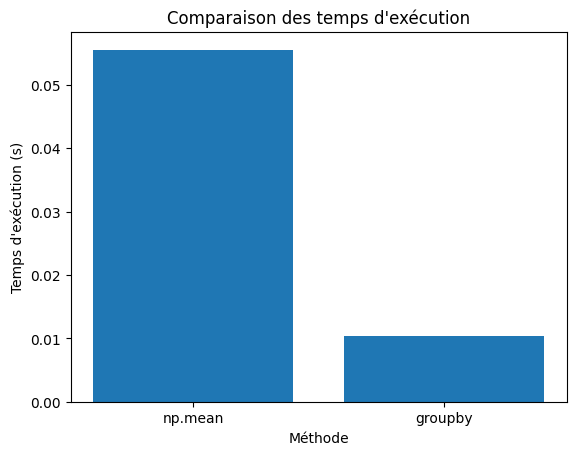

In [20]:
# Création d'un ensemble de données de test
np.random.seed(0)
# Mesure du temps d'exécution de l'approche utilisant np.mean
start_time_np_mean = time.time()
for category in ['Carbonne', 'Decarbonne', 'Normal']:
    np.mean(train['MixProdElec'] == category)
end_time_np_mean = time.time()

# Mesure du temps d'exécution de l'approche utilisant groupby
start_time_groupby = time.time()
n = len(train)
prior = train.groupby(by=['MixProdElec']).size().div(n)
end_time_groupby = time.time()

# Création du graphique
methods = ['np.mean', 'groupby']
execution_times = [end_time_np_mean - start_time_np_mean, end_time_groupby - start_time_groupby]

plt.bar(methods, execution_times)
plt.xlabel('Méthode')
plt.ylabel('Temps d\'exécution (s)')
plt.title('Comparaison des temps d\'exécution')
plt.show()

Il serait donc plus judicieux d'utiliser la fonction groupby pour calculer nos `prior probabilities`.

In [21]:
def compute_prior_probabilities2(data_train, label_column="MixProdElec"):
    """
    Calcule les probabilités a priori pour chaque classe possible pour les valeurs de la colonne <label_columns>.
    
    Args :
    data_train : l'ensemble d'entraînement où la colonne 'y' représente les labels
    
    Retourne :
    Un cadre de données contenant les prior probabilities
    
    """
    n = len(data_train)
    prior=data_train.groupby(by=[label_column]).size().div(n) 
    return prior

Il s'agit d'une solution parmi d'autres qui nous permet d'optimiser notre programme en terme de temps d'execution.


> # **K plus proches voisins**

On importe la bibliothèque scipy qui va nous permettre de calculer des distances.

In [22]:
import scipy
from scipy.spatial.distance import cdist

Dans notre fonction on utilise la fonction np.argsort fournie par la bibliothèque NumPy pour retourner les indices qui trieraient un tableau NumPy dans l'ordre croissant.

On crée un dictionnaire où les clés sont (carbonne, decarbonne, normal) et les valeurs sont le nombre de voisins carbonne, decarbonne ou normal.

Au final,on tient en compte le fait qu’on ait le même nombre de voisins pour deux label et on prend donc au hasard l’un des deux avec la fonction np.random.randint

In [23]:
def knn_predict(k,y_train, distances):
    """
    Effectue une classification par k plus proches voisins sur un seul point de données.
    Args :
     k : le nombre de voisins les plus proches à prendre en compte
     y_train : une liste des labels d'entraînement
     distances : une liste de distances par rapport aux points de données d'apprentissage
    Résultats :
     le label prédit pour un point de données
    """
    sorted_indices= np.argsort(distances)[:k]
    predictions= {}
    max_votes=0
    for index in sorted_indices:
        label= y_train[index]
        if label in predictions:
            predictions[label]+=1
        else:
            predictions[label]=1
        if predictions[label]>max_votes:
            max_votes= predictions[label]
    candidates= [key for key in predictions if predictions[key]== max_votes]
    return candidates[np.random.randint(len(candidates))]

# **Prédictions**

On teste pour k=3.

In [24]:
X_train= train[variables]
X_test= test[variables]
y_train= train["MixProdElec"]

NameError: name 'variables' is not defined

In [ ]:
n=len(test)
k=15
pred_labels= []
#for i in range(n):
    #pred_labels.append(knn_predict (k,y_train,distances[:,i]))

In [ ]:
#submission2= test[['DateTime']]
#submission2['MixProdElec']= pred_labels
#submission2.to_csv("submission2.csv", index=None)

> # **Validation Croisée**

In [ ]:
variables= ["Temperature", "Humidity", "Nebulosity", "Precipitation", "PositionDansAnnee", "WindSpeed"]
X= train[variables]
y= train["MixProdElec"]

Pour la validation croisée,on divise les données en N groupes: N-1 groupes d'entrainement et 1 groupe de test en changeant à chaque fois de groupe de test grace à la fonction split_kfold.

On utilise la fonction *yield* qui est similaire à l'instruction *return*, mais au lieu de renvoyer une valeur et terminer l'exécution de la fonction, elle renvoie temporairement une valeur et met en pause l'exécution de la fonction.

In [ ]:
def split_kfold(X,y, n_splits):
    """
    Divise un jeu de données `X` et ses labels correspondants `y` en `n_splits` plis pour la validation croisée k-fold.
 
    Args :
     X : un DataFrame pandas contenant les caractéristiques de l'ensemble de données
     y : une pandas Series contenant les labels de l'ensemble de données
     n_splits : le nombre de plis pour diviser l'ensemble de données 
    """
    # Taille de chaque groupe
    group_size = len(X) // n_splits
    
    # Division des données
    for i in range(n_splits):
        # Indices pour le groupe de test
        test_start = i * group_size
        test_end = (i + 1) * group_size
        index_test = range(test_start, test_end)

        # Indices pour les groupes d'entraînement
        index_train = [idx for idx in range(len(X)) if idx not in index_test]

        # Données d'entraînement et de test
        X_train= [X.iloc[idx] for idx in index_train]
        X_test= [X.iloc[idx] for idx in index_test]
        y_train= [y.iloc[idx] for idx in index_train]
        y_test= [y.iloc[idx] for idx in index_test]

        yield X_train, y_train, X_test, y_test

Avec la fonction split_kfold, il est moins pratique d'utiliser tout les groupes à la fois par la suite. On a décidé donc d'écrire une fonction split_kfold2 qui stocke tout les groupes dans des listes d'entrainements et de test pour pouvoir y accéder par indice.

In [ ]:
def split_kfold2(X,y,n_splits):
    """
    Divise un jeu de données `X` et ses labels correspondants `y` en `n_splits` plis pour la validation croisée k-fold.
 
    Args :
      X : un DataFrame pandas contenant les caractéristiques de l'ensemble de données
      y : une pandas Series contenant les labels de l'ensemble de données
      n_splits : le nombre de plis à diviser l'ensemble de données
    
    Résultats :
      Listes de plis de données d'entrainement et de test.
    """
    # Initialisation de listes pour stocker les groupes d'entraînement et de test
    X_train_groups, y_train_groups, X_test_groups, y_test_groups = [], [], [], []
    # Utilisation de la fonction split_kfold1
    for X_train, y_train, X_test, y_test in split_kfold(X,y,n_splits):
        # Ajouter chaque groupe d'entraînement et de test aux listes respectives
        X_train_groups.append(X_train)
        X_test_groups.append(X_test)
        y_train_groups.append(y_train)
        y_test_groups.append(y_test)
    return X_train_groups, y_train_groups, X_test_groups, y_test_groups

In [ ]:
X_train_groups, y_train_groups, X_test_groups, y_test_groups = split_kfold2(X,y,5)

On définit la fonction *compute_accuracy* qui retourne le pourcentage de la précision de nos prédiction par rapport à l'ensemble de test. Cette fonction nous servira à évaluer notre fonction *knn_predict* par la suite.

In [ ]:
def compute_accuracy(y_pred, y_true):
    """
    Calcule la précision d'un ensemble de prédictions `y_pred` par rapport à 
    un ensemble de labels vrais `y_true`.

    Args :
      y_pred : une liste d'étiquettes prédites
      y_true : une liste d'étiquettes vraies
    
    Retourne :
      le rapport entre le nombre de prédictions correctes et le nombre total de prédictions.
    """
    sum=0
    for i in range(len(y_pred)):
        if y_pred[i]==y_true[i]:
            sum+=1
    return sum/len(y_pred)

In [ ]:
def choose_best_k(k_values):
    """
    Effectue une validation croisée k-fold pour une liste donnée de valeurs k et renvoie la valeur 
    k qui donne la précision moyenne la plus élevée. 
    
    Args :
      k_values : liste de k à tester
    
    Retourne :
      k_max : la meilleure valeur de k
    """
    max_accuracy = 0
    k_max = 1
    n = len(y_test_groups[0])
    accuracies = [[] for _ in range(len(k_values))]
    for p in range(len(k_values)):
        for j in range(len(y_test_groups)):
            distances = cdist(X_train_groups[j], X_test_groups[j])
            pred_labels = []
            for i in range(n):
                pred_labels.append(knn_predict(k_values[p], y_train_groups[j], distances[:, i]))
            accuracies[p].append(compute_accuracy(pred_labels, y_test_groups[j]))
    for i in range(len(k_values)):
        if (np.mean(accuracies[i]) > max_accuracy):
            max_accuracy = np.mean(accuracies[i])
            k_max = k_values[i]
    return k_max

> # **Arbres de décision**

In [ ]:
def gini_impurity(labels):
    """
    Calcule l'impureté de Gini pour un ensemble d'étiquettes.

    Args :
        labels (numpy.ndarray) : Un tableau d'étiquettes.

    Retourne :
        float : La valeur d'impureté de Gini.
    """
    # Compter le nombre total d'étiquettes
    total_count = len(labels)
    
    # Compter le nombre d'occurrences de chaque classe
    unique_labels,class_counts = np.unique(labels, return_counts=True)
    #la fonction return_counts=True renvoie non seulement les valeurs uniques, mais 
        #le nombre d'occurences de ces valeurs dans le tableau
    
    # Calculer la probabilité de chaque classe
    class_probabilities =class_counts / total_count
    
    # Calculer l'impureté de Gini
    gini_impurity = 1 - np.sum(np.square(class_probabilities))
    
    return gini_impurity

In [ ]:
labels=np.array(train['MixProdElec'])
gini_impurity(labels)
#une impureté de Gini de 0.6638469403019214 indique qu'il y a une certaine diversité dans les étiquettes extraites de la colonne 'MixProdElec'.

Une impureté de Gini de 0.6638469403019214 indique qu'il y a une certaine diversité dans les étiquettes extraites de la colonne 'MixProdElec'.

In [ ]:
def split_data(data, labels, feature_index, threshold):
    """
    Divise les données et les étiquettes en fonction d'une caractéristique et d'un seuil.

    Args:
        data (pandas.DataFrame): Les données d'entrée.
        labels (numpy.ndarray): Les étiquettes correspondantes.
        feature_index (int): L'index de la caractéristique à utiliser pour la division.
        threshold (str): La valeur de seuil pour la division (doit correspondre au type de données de la caractéristique).

    Returns:
        tuple: Un tuple contenant la division gauche et droite des données et des étiquettes.
    """
    # Sélectionne les données à gauche de la division en fonction du seuil de la caractéristique
    left_data = data[data.iloc[:, feature_index] < threshold]
    # Sélectionne les étiquettes correspondantes pour les données à gauche
    left_labels = labels[data.iloc[:, feature_index] < threshold]
    # Sélectionne les données à droite de la division en fonction du seuil de la caractéristique
    right_data = data[data.iloc[:, feature_index] >= threshold]
    # Sélectionne les étiquettes correspondantes pour les données à droite
    right_labels = labels[data.iloc[:, feature_index] >= threshold]

    return left_data, left_labels, right_data, right_labels

In [ ]:
etiquettes = np.array(train['MixProdElec'])  # Labels correspondant aux données

feature_index = 2  # Index de la caractéristique à utiliser pour le split
threshold = 250  # Seuil de division

# Appel de la fonction split_data avec les données de test
left_data, left_labels, right_data, right_labels = split_data(train, labels, feature_index, threshold)
left_data, left_labels, right_data, right_labels

In [ ]:
def find_best_split(data, labels):
    """
    Trouve la meilleure division pour un ensemble de données donné.

    Args:
        data (pandas.DataFrame): Les données d'entrée.
        labels (numpy.ndarray): Les étiquettes correspondantes.

    Returns:
        tuple: Un tuple contenant le meilleur index de caractéristique et la meilleure valeur de seuil.
    """
    best_feature_index = None
    best_threshold = None
    best_gini = float('inf')  # L'indice de Gini initial est défini sur l'infini positif
     #float('inf') : float est une fonction qui convertit son argument en un nombre à virgule flottante. 
#L'argument ici est la chaîne de caractères 'inf', qui est une représentation de l'infini positif en Python.

    # Itérer à travers chaque caractéristique (variable) dans l'ensemble de données
    for feature_index in range(data.shape[1]):
        feature_values = data.iloc[:, feature_index]  # Extrait la colonne de la variable caractéristique
        # Itérer à travers les valeurs uniques de la caractéristique comme des seuils potentiels
        for threshold in feature_values.unique():
            # Divise les données et les étiquettes en fonction de la caractéristique et du seuil actuels
            left_data, left_labels, right_data, right_labels = split_data(data, labels, feature_index, threshold)
            
            # Calcule l'impureté de Gini pour les divisions gauche et droite
            gini_left = gini_impurity(left_labels)
            gini_right = gini_impurity(right_labels)
            
    # cette ligne de code est utilisée dans le contexte de la construction d'un arbre de décision pour évaluer la qualité 
    #d'une division potentielle des données en calculant l'indice de Gini pondéré pour cette division
            weighted_gini = (len(left_data) * gini_left + len(right_data) * gini_right) / len(data)

            # Met à jour la meilleure division si la division actuelle a une impureté de Gini inférieure
            if weighted_gini < best_gini:
                best_gini = weighted_gini
                best_feature_index = feature_index
                best_threshold = threshold

    return best_feature_index, best_threshold

Maintenant, nous allons appeler la fonction find_best_split pour effectuer un test sur des données simples.

In [ ]:
# Création d'un ensemble de données synthétique
data = pd.DataFrame({
    'Feature1': [1, 2, 3, 4, 5],
    'Feature2': [2, 3, 4, 5, 6],
    'Feature3': [3, 4, 5, 6, 7],
    'Feature4': [4, 5, 6, 7, 8],
    'Labels': ['A', 'B', 'A', 'B', 'A']
})

# Séparation des données en features et labels
features = data.drop(columns=['Labels'])  # Sélection des caractéristiques en supprimant la colonne 'Labels'
labels = np.array(data['Labels'])  # Extraction des étiquettes comme un tableau numpy

# Test de la fonction find_best_split

# Appel de la fonction find_best_split avec les caractéristiques et les étiquettes
best_feature_index, best_threshold = find_best_split(features, labels)

# Affichage des résultats
print("Meilleur index de caractéristique:", best_feature_index)
print("Meilleur seuil:", best_threshold)

In [ ]:
# Définition de la fonction pour construire un arbre de décision de manière récursive
def build_tree(data, labels, max_depth, min_samples_split, depth=0):
    """
    Construit un arbre de décision de manière récursive.

    Args:
        data (pandas.DataFrame): Les données d'entrée.
        labels (numpy.ndarray): Les étiquettes correspondantes.
        max_depth (int): La profondeur maximale de l'arbre.
        min_samples_split (int): Le nombre minimum d'échantillons requis pour diviser un nœud.
        depth (int, optionnel): La profondeur actuelle de l'arbre. La valeur par défaut est 0.

    Retourne:
        dict: L'arbre de décision représenté sous la forme d'un dictionnaire.
    """
    node = {}  # Initialisation d'un nœud vide pour l'arbre
    
    unique_classes = np.unique(labels)  # Trouver les classes uniques dans les étiquettes
    
    # Vérifier si toutes les étiquettes sont de la même classe ou si la profondeur maximale est atteinte
    if len(unique_classes) == 1 or depth == max_depth:
        node['class'] = unique_classes[0]  # Attribuer la classe unique ou la classe majoritaire si la profondeur maximale est atteinte
        return node
    
    # Vérifier si le nombre d'échantillons est inférieur au seuil de division minimum
    if len(data) < min_samples_split:
        node['class'] = np.argmax(np.bincount(labels))  # Attribuer la classe majoritaire
        return node
    
    # Trouver la meilleure division pour les données actuelles
    best_feature_index, best_threshold = find_best_split(data, labels)
    
    # Diviser les données en fonction de la meilleure division
    left_data, left_labels, right_data, right_labels = split_data(data, labels, best_feature_index, best_threshold)
    
    # Ajouter les informations sur la division et les sous-arbres gauche et droit au nœud actuel
    node['feature_index'] = best_feature_index
    node['threshold'] = best_threshold
    node['left'] = build_tree(left_data, left_labels, max_depth, min_samples_split, depth + 1)  # Construction récursive de l'arbre pour le sous-ensemble gauche
    node['right'] = build_tree(right_data, right_labels, max_depth, min_samples_split, depth + 1)  # Construction récursive de l'arbre pour le sous-ensemble droit
    
    return node  # Retourne le nœud actuel avec ses sous-arbres construits

In [ ]:
labels = np.array([0, 1, 0, 1, 0])  # Labels binaires correspondants

# Paramètres de l'arbre de décision
max_depth = 3
min_samples_split = 2

# Appel de la fonction pour construire l'arbre
decision_tree = build_tree(data, labels, max_depth, min_samples_split)

# Affichage de l'arbre construit
print(decision_tree)

In [ ]:
def predict(tree, data_point):
    """
    Faire une prédiction pour un seul point de données en utilisant l'arbre de décision.

    Args :
        tree (dict) : L'arbre de décision représenté sous la forme d'un dictionnaire.
        data_point (numpy.ndarray) : Le point de données en entrée.

    Retourne :
        int : L'étiquette de classe prédite.
    """
    # Si le nœud est une feuille, retourner la classe prédite
    if 'class' in tree:
        return tree['class']
    
    # Sinon, comparer la valeur de la caractéristique du point de données avec le seuil
    if data_point[tree['feature_index']] < tree['threshold']:
        # Si la valeur de la caractéristique est inférieure au seuil, descendre dans le sous-arbre gauche
        return predict(tree['left'], data_point)
    else:
        # Sinon, descendre dans le sous-arbre droit
        return predict(tree['right'], data_point)

In [ ]:
# Supposons que nous avons un arbre de décision représenté comme suit :

decision_tree = {
    'feature_index': 1,                          # Index de la caractéristique utilisée pour la division
    'threshold': 4.0,                            # Valeur de seuil pour la division
    'left': {'class': 0},                        # Sous-arbre gauche (si la condition est vérifiée)
    'right': {
        'feature_index': 0,                      # Index de la caractéristique utilisée pour une autre division dans le sous-arbre droit
        'threshold': 2.5,                        # Valeur de seuil pour la division dans le sous-arbre droit
        'left': {'class': 1},                    # Sous-arbre gauche du sous-arbre droit
        'right': {'class': 0}                    # Sous-arbre droit du sous-arbre droit
    }
}

# Supposons un point de données à prédire :
data_point = np.array([3.0, 3.5])       # Caractéristiques du point de données

# Nous pouvons appeler la fonction de prédiction comme suit :
predicted_class = predict(decision_tree, data_point)

# Enfin, nous imprimons l'étiquette de la classe prédite :
print("Étiquette de Classe Prédite:", predicted_class)
     

> # **Forêts Aléatoires**

Pour construire, une forêt aléatoire, on va utilise la méthode du BOOTSTRAP qui est une méthode de rééchantillonnage avec remise. Cela signifie que chaque élément de l'ensemble de données original a la même probabilité d'être sélectionné pour former une partie de l'ensemble de données bootstrap. Cela a pour objectif d'augmenter la variabilité de l’ensemble d’apprentissage.

On implémente donc la fonction *bootstrap* suivante:

In [ ]:
def bootstrap(data, n, n_var, n_echantillon):
    """
    Renvoie une liste de jeux de données bootstrap et la liste des variables sélectionnées 
    pour chaque jeu de données.
    
    Args:
    data : l'ensemble de données d'origine à partir duquel les jeux de données bootstrap 
           seront échantillonnés
    n: le nombre de jeux de données bootstrap à générer.
    n_var : le nombre de variables descriptives (colonnes) à sélectionner aléatoirement 
            pour chaque jeu de données.
    n_echantillon : le nombre d'observations (lignes) à échantillonner pour chaque jeu de données.
    
    Returns:
    res: une liste de jeux de données
    selected_var_list: la liste des variables sélectionnées pour chaque jeu de données
    """
    # Initialisation des listes pour stocker les résultats
    res = []
    selected_var_list = []
    
    # Boucle pour générer les jeux de données bootstrap
    for i in range(n):
        # Sélection aléatoire des indices de colonnes
        selected_var = np.random.choice(np.arange(len(data.columns)), size=n_var, replace=False)
        # Ajout des indices sélectionnés à la liste
        selected_var_list.append(selected_var)
        # Échantillonnage des observations et sélection des colonnes correspondantes
        bootstrapped_df = data.sample(n=n_echantillon, replace=False).iloc[:, selected_var]
        # Ajout du jeu de données bootstrap à la liste
        res.append(bootstrapped_df)     
        
    # Retour des jeux de données bootstrap et des indices des variables sélectionnées
    return res, selected_var_list


In [ ]:
boot=bootstrap(train, 2, 3, 2)
boot